# Motivation and intention

Same as `reproducing-silverman2019.ipynb`, but using a model that has fewer trainable parameters, optimised such that the validation accuracy is 95%.

Kernel 2x3. With 8-channel into 8 channel into 88 dense into 5 classes, we find:
- training accuracy of 99.85 percent (98.07 percent with all data augs)
- validation accuracy of 99.81 percent (98.04 percent with all data augs)

Kernel 3x3. With 4-channel into 8-channel into 32 dense into 5 classes, we find
- Training accuracy of 99.77 percent
- validation accuracy of 99.48 percent

Kernel 3x3. With 4-channel into 4-channel into 2x2 maxpool into 8-channel into 32 dense into 5 classes, we find
- Training accuracy of 99.69 percent
- Validation accuracy of 99.61 percent

Kernel 3x3. With 4-channel into 4-channel in 2x2 maxpool into 4-channel into 4-channel into 16 dense into 5 classes
- Training accuarcy of 99.69 percent
- Validation accuracy of 99.64 percent

*Kernel 2x2. With 4-channel into 4-channel in 2x2 maxpool into 4-channel into 4-channel into 16 dense into 5 classes (fewer than 400 params!)*
- Training accuracy of 99.11 percent
- Validation accuracy of 99.10 percent (but can be trained better)
- FOR RULES (change ..-16-5 to ..-256), we find training acc of 66.90, val acc of 67.10

# Loading packages and functions

In [1]:
# !pip install cellpylib
# import cellpylib as cpl

# TensorFlow and tf.keras
import tensorflow as tf
from tensorflow import keras

print(tf.__version__)

# Helper libraries
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
import pandas as pd
import os
import json

# fix random seed for reproducibility
seed = 2023
np.random.seed(seed)

from sklearn.model_selection import train_test_split

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalMaxPooling2D
from tensorflow.keras.constraints import max_norm
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model
from tensorflow.keras import Input

2.15.0


In [2]:
gpu_info = !nvidia-smi
gpu_info = '\n'.join(gpu_info)
if gpu_info.find('failed') >= 0:
  print('Not connected to a GPU')
else:
  print(gpu_info)

Thu Feb 22 10:34:07 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  Tesla T4                       Off | 00000000:00:04.0 Off |                    0 |
| N/A   44C    P8               9W /  70W |      0MiB / 15360MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [4]:
# uncomment if you want to use Drive

from google.colab import drive
drive.mount('/content/gdrive')

images_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Images'
models_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models'
files_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'
# !ls '/content/gdrive/My Drive/'

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [5]:
# Load function to show accuracy and loss history

def plot_history(history, steps_per_epoch = 0, y_axis_bounds = None, show_val=True, show_loss=True):

    if steps_per_epoch >0:
        xvals = int(steps_per_epoch)*np.array(history.epoch)
        xlab = 'Weight update steps'
    else:
        xvals = np.array(history.epoch)
        xlab = 'Epochs'

    if show_loss:
      plt.figure(figsize = (12,4))
      plt.subplot(1,2,1)
    else:
      plt.figure(figsize= (6,4))
    plt.xlabel(xlab)
    plt.ylabel('Accuracy')
    plt.plot(xvals, np.array(history.history['accuracy']),'g-',
             label='Train accuracy')
    if show_val:
      plt.plot(xvals, np.array(history.history['val_accuracy']),'r-',
             label = 'Validation accuracy')
    if y_axis_bounds:
        plt.ylim(y_axis_bounds)
    plt.legend()

    if show_loss:
      plt.subplot(1,2,2)
      plt.xlabel(xlab)
      plt.ylabel('Loss minimised by model')
      plt.plot(xvals, np.array(history.history['loss']),'g-',
              label='Train loss')
      if show_val:
        plt.plot(xvals, np.array(history.history['val_loss']),'r-',
              label = 'Validation loss')
    plt.legend()

In [6]:
# Load function to translate rule to Li-Packard classes (for loading/showing data)
# Note: This function is very poorly designed (slow)

def whichClass(dictionary, rules, class_to_num=None):
    keys = []
    for i, rule in enumerate(rules):
      for key, array in dictionary.items():
          if np.isin(rule, array):
            if class_to_num: # digits rather than strings
              keys.append(class_to_num[key])
            else: # strings rather than digits
              keys.append(key)
    return np.array(keys)

# Loading and showing data

In [7]:
# Load and shuffle data in a stratified fashion
ONLY_LOAD_TEST = False

# Choose validation set fraction
val_frac = 1/4

train_name_prefix = "ECAs_1024sims-per-rule_64x64"
train_diagram_name = train_name_prefix + "_train_diagrams.npy"
train_label_name = train_name_prefix + "_train_labels.npy"

test_name_prefix = "ECAs_128sims-per-rule_64x64"
test_diagram_name = test_name_prefix + "_test_diagrams.npy"
test_label_name = test_name_prefix + "_test_labels.npy"

if not ONLY_LOAD_TEST:
  x_train_all = np.load(f"{files_dir}/{train_diagram_name}")
  r_train_rule_all = np.load(f"{files_dir}/{train_label_name}")
x_test_all = np.load(f"{files_dir}/{test_diagram_name}")
r_test_rule_all = np.load(f"{files_dir}/{test_label_name}")

if not ONLY_LOAD_TEST:
  # take examples from the data set to show below
  rules_example = np.array([168, 232, 178, 154, 161]) # final rules in table of Li-Packard
  indices_example = int(x_train_all.shape[0]/256)*rules_example
  x_train_example = np.take(x_train_all, indices_example, axis=0)
  r_train_example = np.take(r_train_rule_all, indices_example, axis=0)

  # Shuffle test data at random, keeping the relation between diagrams and labels
  shuffle_indices = np.random.permutation(range(r_train_rule_all.shape[0]))
  x_train_all = x_train_all[shuffle_indices]
  r_train_rule_all = r_train_rule_all[shuffle_indices]

  # Split training data in a training and validation set
  val_size = int(x_train_all.shape[0]*val_frac)
  x_train, x_val, r_train_rule, r_val_rule = train_test_split(x_train_all, r_train_rule_all, test_size=val_size, random_state=0, shuffle=True, stratify=r_train_rule_all)

# Translate rule to Li-Packard class
with open(f"{files_dir}/all_Li-Packard_dict.json", "r") as fp:
    # Load the dictionary from the file
    Li_Packard_dict = json.load(fp)

# Change key names to digits
class_to_num = dict({'null':0, 'fixed point':1, 'periodic':2, 'locally chaotic':3, 'chaotic':4})
num_to_class = dict({0:'null', 1:'fixed point', 2:'periodic', 3:'locally chaotic', 4:'chaotic'})

if not ONLY_LOAD_TEST:
  r_train_class = np.empty(r_train_rule.shape)
  r_train_class_all = np.empty(r_train_rule_all.shape)
  r_val_class = np.empty(r_val_rule.shape)
r_test_class_all = np.empty(r_test_rule_all.shape)

if not ONLY_LOAD_TEST:
  # This step takes a while because of a poorly written function
  r_train_class[:,0] = whichClass(Li_Packard_dict, r_train_rule[:,0], class_to_num=class_to_num)
  r_train_class_all[:,0] = whichClass(Li_Packard_dict, r_train_rule_all[:,0], class_to_num=class_to_num)
  r_val_class[:,0] = whichClass(Li_Packard_dict, r_val_rule[:,0], class_to_num=class_to_num)
r_test_class_all[:,0] = whichClass(Li_Packard_dict, r_test_rule_all[:,0], class_to_num=class_to_num)


if not ONLY_LOAD_TEST:
  # Translate to one-hot vectors for cross entropy loss function
  r_train5 = keras.utils.to_categorical(r_train_class)
  r_train5_all = keras.utils.to_categorical(r_train_class_all)
  r_val5 = keras.utils.to_categorical(r_val_class)
r_test5_all = keras.utils.to_categorical(r_test_class_all)

if not ONLY_LOAD_TEST:
  r_train256 = keras.utils.to_categorical(r_train_rule)
  r_train256_all = keras.utils.to_categorical(r_train_rule_all)
  r_val256 = keras.utils.to_categorical(r_val_rule)
r_test256_all = keras.utils.to_categorical(r_test_rule_all)

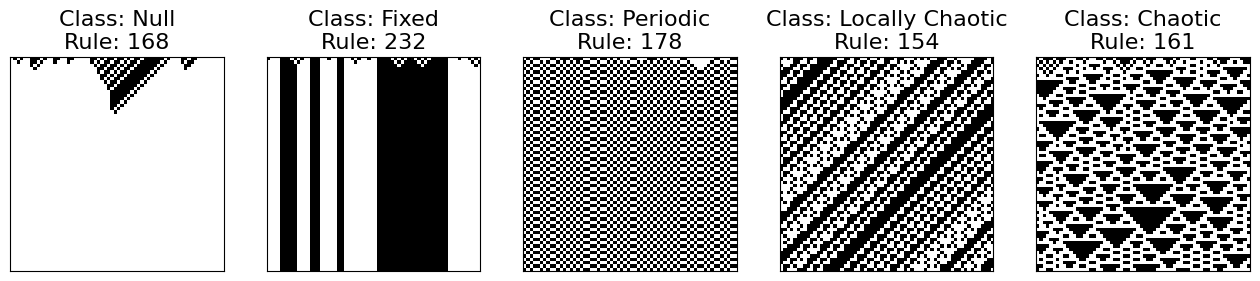

In [10]:
# Generate examples from every class (chosen deterministically earlier)
SAVEFIG=False
SAVENAME="LP-classes-examples.pdf"

figsize=16
title_size=16
fig, axs = plt.subplots(1,5, figsize=(figsize, 5*figsize))
LP_classes_example = ["Null","Fixed","Periodic","Locally Chaotic","Chaotic"]
for i in range(5):
  class_rule = r_train_example[i,0]
  class_name = LP_classes_example[i]
  axs[i].imshow(x_train_example[i, :, :, 0], cmap='Greys')
  axs[i].set_title(f"Class: {class_name}\nRule: {class_rule}", size=title_size)
  axs[i].set_xticks([])
  axs[i].set_yticks([])

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

# Designing and running the convolutional neural network

In [11]:
def silverman_model_trimmed(diagram_dims=(64, 64, 1), conv_kernel_dims=(3,3), dilation_rate=(1,1), output_type='classes'):
    # output_type param should be 'classes' or 'rules'

    # tell the model which input shape the samples will have
    inputs = Input(diagram_dims, dtype=tf.float32)

    # Conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid', dilation_rate=dilation_rate)(inputs)
    x = Activation('relu')(x)

    # Conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid', dilation_rate=dilation_rate)(x)
    x = Activation('relu')(x)

    # MaxPool layer 2x2
    x = MaxPooling2D()(x)

    # conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid')(x)
    x = Activation('relu')(x)

    # conv block, width = 4
    x = Conv2D(4, conv_kernel_dims, padding='valid')(x)
    x = Activation('relu')(x)

    # global max pooling
    x = GlobalMaxPooling2D()(x)

    # and finally the linear classification output layer
    if output_type=='classes':
      x = Dense(16)(x)
      output = Dense(5, activation="softmax")(x)
    elif output_type=='rules':
      output = Dense(256, activation="softmax")(x)
    else:
      raise Exception("Parameter 'output_type' should be either 'classes' (5-fold) or 'rules' (256-fold).")
    model = tf.keras.Model(inputs=inputs, outputs=output)

    # Note that, in contrast to the first graded assignment,
    # we have taken the model compilation out of this function (it is done in the model training block)

    return model

In [16]:
RUN_AGAIN = True
SAVE_AGAIN = True
model_name_rules = "reproducing_silverman2019_trimmed_rules_2x2-4-4-MP-4-4-16"
model_name = "reproducing_silverman2019_trimmed_2x2-4-4-MP-4-4-16"
conv_kernel_dims = (2,2)
dilation_rate = (1,1)
output_type = 'classes'

diagram_dims = (64,64,1)

if output_type == 'rules':
  if not ONLY_LOAD_TEST:
    r_train = r_train256
    r_val = r_val256
    r_train_all = r_train256_all
  r_test_all = r_test256_all
elif output_type == 'classes':
  if not ONLY_LOAD_TEST:
    r_train = r_train5
    r_val = r_val5
    r_train_all = r_train5_all
  r_test_all = r_test5_all

if RUN_AGAIN:
  N_train = x_train.shape[0]
  batch_size = 64
  batches_per_epoch = int(N_train/batch_size)
  epochs = 100
  LR = 0.0005 # I changed this!
  stopping_patience = 10
  stopping_delta = 0.000001

  model_trimmed = silverman_model_trimmed(diagram_dims=diagram_dims,
                                          conv_kernel_dims=conv_kernel_dims,
                                          dilation_rate=dilation_rate,
                                          output_type=output_type)
  model_trimmed.summary()

  model_trimmed.compile(loss='categorical_crossentropy',
                  optimizer=Adam(learning_rate=LR),
                  metrics=['accuracy'])

  stopping_callback = tf.keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                                      patience=stopping_patience,
                                                      min_delta=stopping_delta,
                                                      verbose = 1,
                                                      restore_best_weights=True)

  history_trimmed = model_trimmed.fit(x_train,
                          r_train,
                          batch_size=batch_size,
                          epochs=epochs,
                          verbose=1,
                          validation_data=(x_val, r_val),
                          shuffle=True,
                          callbacks = [stopping_callback])

  if SAVE_AGAIN:
    if output_type == 'rules':
      model_trimmed_rules.save(f"{models_dir}/{model_name}")
    elif output_type == 'classes':
      model_trimmed.save(f"{models_dir}/{model_name}")

else:
  model_trimmed_rules = load_model(f"{models_dir}/{model_name_rules}")
  model_trimmed = load_model(f"{models_dir}/{model_name}")

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 64, 64, 1)]       0         
                                                                 
 conv2d_8 (Conv2D)           (None, 63, 63, 4)         20        
                                                                 
 activation_8 (Activation)   (None, 63, 63, 4)         0         
                                                                 
 conv2d_9 (Conv2D)           (None, 62, 62, 4)         68        
                                                                 
 activation_9 (Activation)   (None, 62, 62, 4)         0         
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 31, 31, 4)         0         
 g2D)                                                            
                                                           

Training set Accuracy:0.989863
Training set Loss:0.034701

Validation set Accuracy:0.989029
Validation set Loss:0.036781



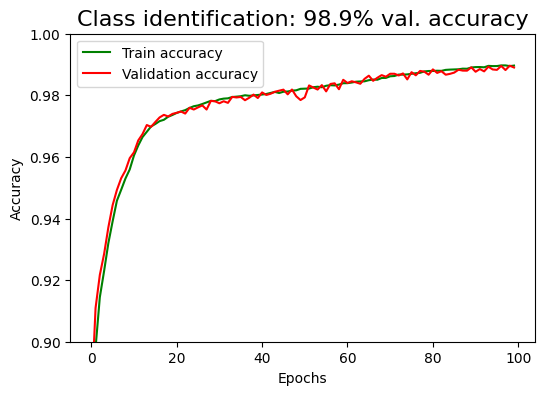

In [18]:
CALCULATE_AGAIN = False
SAVE_FIG = True

if CALCULATE_AGAIN:
  [train_loss, train_accuracy] = model_trimmed.evaluate(x_train, r_train, verbose=1)
  [val_loss, val_accuracy] = model_trimmed.evaluate(x_val, r_val, verbose=1)

print("Training set Accuracy:{:7.6f}".format(train_accuracy))
print("Training set Loss:{:7.6f}\n".format(train_loss))

print("Validation set Accuracy:{:7.6f}".format(val_accuracy))
print("Validation set Loss:{:7.6f}\n".format(val_loss))

#Now we visualise what happened during training
plot_history(history_trimmed, y_axis_bounds=[.9,1], show_loss=False)
plt.title(f'Class identification: {round(100*val_accuracy,2)}% val. accuracy', size=16)

if SAVE_FIG:
  plt.savefig(f'{images_dir}/accuracy-hist_{model_name}.pdf', bbox_inches='tight')

# Analysis of the model performance

2048/2048 [==============================] - 4s 2ms/step


<ipython-input-34-a8fbd0b6bb0f>:50: UserWarning: FixedFormatter should only be used together with FixedLocator
  axs[0].set_xticklabels(num_to_class.keys(), size=labelsize)


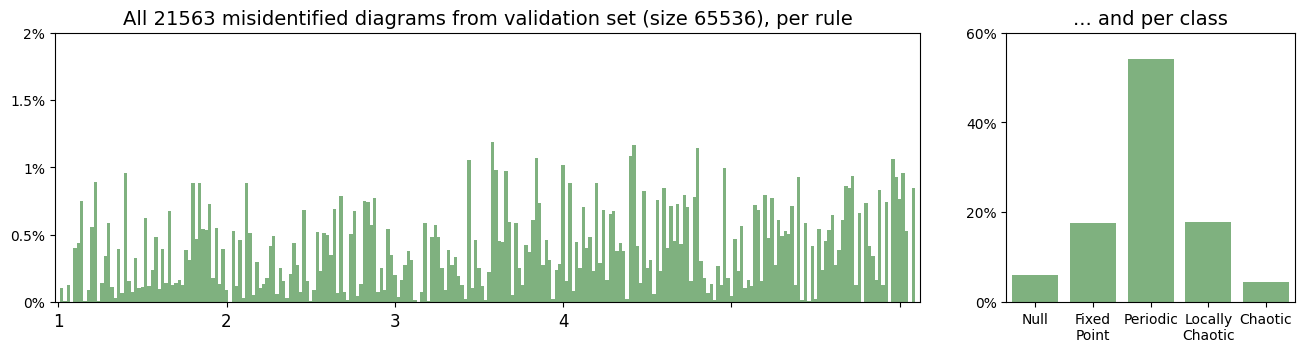

In [34]:
SAVEFIG=False
SAVENAME='trimmed-model_2x2-4-4-MP-4-4-16_misidentified-val-set.pdf'

# the predictions are class probabilities,
# the argmax code line below finds the index of the class with the highest probability
predictions_rules = model_trimmed_rules.predict(x_val)
predictions_classes = model_trimmed.predict(x_val)

val_predicted_rule = np.argmax(predictions_rules,axis=1)
val_predicted_class = np.argmax(predictions_classes, axis=1)

ugent_blue = (30/255,100/255,200/255)
ugent_yellow = (255/255, 210/255, 0/255)

color1 = 'maroon'
color2 = 'darkgreen'

misclassified_rules_idxs, = np.where(val_predicted_rule!=r_val_rule[:,0]) # too much RAM!
misclassified_rules_real = r_val_rule[misclassified_rules_idxs,0]
misclassified_rules_guess = val_predicted_rule[misclassified_rules_idxs]

misclassified_classes_idxs, = np.where(val_predicted_class!=r_val_class[:,0]) # too much RAM!
misclassified_classes_real = r_val_class[misclassified_classes_idxs,0]
misclassified_classes_guess = val_predicted_class[misclassified_classes_idxs]

misclassified_rules_sizes_real = np.array([np.count_nonzero(misclassified_rules_real==i) for i in range(256)])
misclassified_rules_sizes_guess = np.array([np.count_nonzero(misclassified_rules_guess==i) for i in range(256)])

misclassified_classes_sizes_real = np.array([np.count_nonzero(misclassified_classes_real==i) for i in range(5)])
misclassified_classes_sizes_guess = np.array([np.count_nonzero(misclassified_classes_guess==i) for i in range(5)])

fig, axs = plt.subplots(1,2,figsize=(16,3.5), width_ratios=(3,1))
plt.subplots_adjust(wspace=0.15)
labelsize=12

axs[0].bar(np.arange(256), misclassified_rules_sizes_real / sum(misclassified_rules_sizes_real), width=1,
       color=color2, alpha=.5,
       label='Real rule of misidentified diagram')

axs[1].bar(np.arange(5), misclassified_classes_sizes_real / sum(misclassified_classes_sizes_real), width=.8,
       color=color2, alpha=.5,
       label='Real rule of misidentified diagram')

axs[0].set_xlim([-1,256])
# axs[0].set_ylim([0, 0.07])
axs[0].set_ylim([0, 0.02])
# axs[0].set_yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07])
axs[0].set_yticks([0, 0.005, 0.01, 0.015, 0.020])
axs[0].set_yticklabels(['0%', '0.5%', '1%', '1.5%', '2%'])
axs[0].set_xticklabels(num_to_class.keys(), size=labelsize)

axs[1].set_ylim([0, .6])
axs[1].set_yticks([0, 0.2, 0.4, 0.6])
axs[1].set_yticklabels(['0%', '20%', '40%', '60%'])

axs[1].set_xlim([-.5,4.5])
axs[1].set_xticks([0, 1, 2, 3, 4])
xticklabels=['Null','Fixed\nPoint', 'Periodic','Locally\nChaotic','Chaotic']
axs[1].set_xticklabels(xticklabels)
# axs[1].set_ylim([0, 0.07])
# axs[1].set_yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07])
# axs[1].set_yticklabels(['0%', '1%', '2%', '3%', '4%', '5%', '6%', '7%'])
# axs[1].set_xticklabels(num_to_class.keys(), size=labelsize)

# ax.legend(prop={'size':labelsize}, ncols=2, loc='upper left')
axs[0].set_title(f"All {len(misclassified_rules_idxs)} misidentified diagrams from validation set (size {r_val_rule.shape[0]}), per rule", fontsize=labelsize+2)
axs[1].set_title(f"... and per class", fontsize=labelsize+2)

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

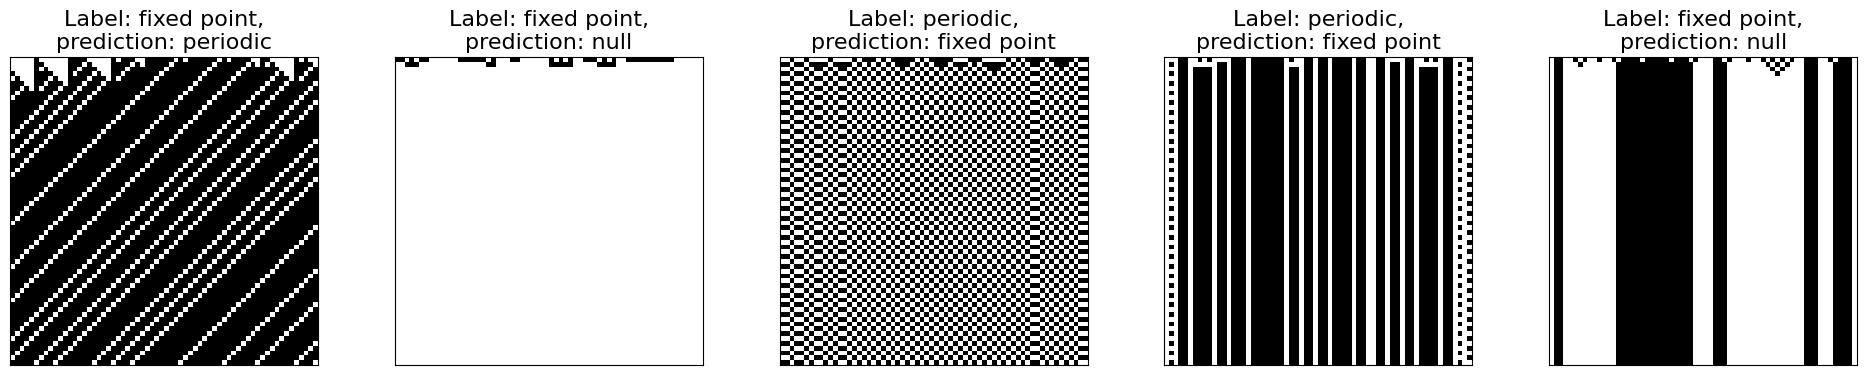

In [27]:
# Show which diagram has been classified wrongly



fix, axs = plt.subplots(1, 5, figsize=(24, 4))

for i in range(5):
  mis_index = np.random.choice(misclassified_classes_idxs)
  actual_class = num_to_class[int(r_val_class[mis_index,0])]
  predicted_class = num_to_class[int(val_predicted_class[mis_index])]
  axs[i].set_title("Label: " + actual_class
          + ",\nprediction: " + predicted_class, size=16)
  axs[i].imshow(x_val[mis_index,:,:,0], cmap='Greys', interpolation='None')
  axs[i].set_xticks([])
  axs[i].set_yticks([])

Note how the "misclassified" periodic diagrams are often quite logical.